<a href="https://colab.research.google.com/github/natsakh/ElectromagneticNets/blob/main/TimeVaryingMedia/PINNs/InitialValueProblems/AnalyticalBenchmarks/3_quadratic_temporal_ramp_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quadratic Temporal Ramp Benchmark

This notebook reproduces the quadratic temporal-ramp results reported in
*Physics-Informed Neural Networks for Electromagnetic Wave Propagation in
Time-Varying Media: Analytical Benchmarks for Initial-Value Problems*.

Running the notebook from top to bottom trains the global SIREN PINN for
$T_{\rm ramp}/T_0=1,3,5$, reports the corresponding five-run statistics from
Table 3, and generates the quadratic ramp column of Figure 4. The analytical
solution is used only for numerical evaluation; no labeled field data are used
during training.


In [ ]:
from pathlib import Path
import csv
import json
import time
import random
import math

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from datetime import datetime

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

from google.colab import drive
drive.mount("/content/drive")

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
EXPERIMENT = f"quadratic_temporal_ramp_{timestamp}"

BASE_DIR = Path("/content/drive/MyDrive/TimeVaryingMedia")
OUTPUT_DIR = BASE_DIR / EXPERIMENT
MODELS_DIR = OUTPUT_DIR / "models"
LOSS_DIR = OUTPUT_DIR / "loss_history"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"

for directory in [OUTPUT_DIR, MODELS_DIR, LOSS_DIR, PREDICTIONS_DIR, TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Saving to:", OUTPUT_DIR)


## Problem definition

The separated complex amplitudes satisfy

\[
\frac{dD}{dt}=\frac{i k_1}{\mu_0}B,
\qquad
\frac{dB}{dt}=\frac{i k_1}{\varepsilon_0 n(t)^2}D.
\]

The network has four real outputs: \(\Re D,\Im D,\Re B,\Im B\).

In [ ]:
# Physical parameters
n1 = 1.5
n2 = 1.8
omega1 = 2 * np.pi
E0 = 1.0

epsilon0 = 1.0
mu0 = 1.0
c = 1.0

T0 = 2 * np.pi / omega1
omega2 = n1 / n2 * omega1
k1 = n1 * omega1 / c

D0 = epsilon0 * n1**2 * E0
H0 = n1 / (mu0 * c) * E0
B0 = mu0 * H0


## Experiment configuration

The physical parameters, three ramp durations, temporal horizon, network, and
training settings below reproduce the configuration reported in the paper.


In [ ]:
# ============================================================
# USER CONFIGURATION
# ============================================================
MODULATION = "quadratic_ramp"
RUN_METHODS = ["global_siren"]

SEEDS = [42, 43, 44, 45, 46]

RAMP_DURATIONS = [1.0, 3.0, 5.0]  # T_ramp / T0

TAU_MAX_BY_METHOD = {
    "global_siren": 20.0,
}

COMMON_EVAL_TAU_MAX = 5.0

# ============================================================
# FIXED SETTINGS
# ============================================================
VALID_METHODS = {"global_siren"}
unknown = set(RUN_METHODS) - VALID_METHODS
if unknown:
    raise ValueError(f"Unknown methods: {sorted(unknown)}")

if MODULATION != "quadratic_ramp":
    raise NotImplementedError(
        "This notebook contains the quadratic-ramp physics and exact reference only."
    )

if COMMON_EVAL_TAU_MAX > min(TAU_MAX_BY_METHOD[m] for m in RUN_METHODS):
    raise ValueError("COMMON_EVAL_TAU_MAX must be covered by the selected horizon.")

if any(r <= 0 for r in RAMP_DURATIONS):
    raise ValueError("All ramp durations must be positive.")

N_COLLOCATION_PER_PERIOD = 500
ADAM_EPOCHS = 10000
ADAM_LEARNING_RATE = 1e-3

LBFGS_MAX_ITER = 1000
LBFGS_HISTORY_SIZE = 100
LBFGS_TOLERANCE_GRAD = 1e-9
LBFGS_TOLERANCE_CHANGE = 1e-12
LBFGS_LINE_SEARCH_FN = "strong_wolfe"

IC_WEIGHT = 20.0
GRAD_CLIP = 1.0
N_EVAL_PER_PERIOD = 500

HIDDEN_LAYERS = 4
HIDDEN_DIM = 64
ARCHITECTURE = f"{HIDDEN_LAYERS}x{HIDDEN_DIM}"

# Known incident frequency; never replace by the shifted omega2.
SIREN_OMEGA = omega1

CONFIG = {
    "benchmark": MODULATION,
    "n1": float(n1),
    "n2": float(n2),
    "experiment_question": "final_quadratic_ramp_global_siren_benchmark",
    "run_methods": RUN_METHODS,
    "tau_max_by_method": TAU_MAX_BY_METHOD,
    "common_eval_tau_max": COMMON_EVAL_TAU_MAX,
    "ramp_durations": RAMP_DURATIONS,
    "quadratic_shape_alpha": -1.0,
    "seeds": SEEDS,
    "physical_parameters": {
        "n1": float(n1),
        "n2": float(n2),
        "omega1": float(omega1),
        "omega2": float(omega2),
        "E0": float(E0),
        "epsilon0": float(epsilon0),
        "mu0": float(mu0),
        "c": float(c),
        "T0": float(T0),
        "k1": float(k1),
    },
    "n_collocation_per_period": N_COLLOCATION_PER_PERIOD,
    "adam_epochs": ADAM_EPOCHS,
    "adam_learning_rate": ADAM_LEARNING_RATE,
    "lbfgs_max_iter": LBFGS_MAX_ITER,
    "lbfgs_history_size": LBFGS_HISTORY_SIZE,
    "lbfgs_tolerance_grad": LBFGS_TOLERANCE_GRAD,
    "lbfgs_tolerance_change": LBFGS_TOLERANCE_CHANGE,
    "lbfgs_line_search_fn": LBFGS_LINE_SEARCH_FN,
    "ic_weight": IC_WEIGHT,
    "grad_clip": GRAD_CLIP,
    "n_eval_per_period": N_EVAL_PER_PERIOD,
    "optimizer": "Adam + L-BFGS",
    "architecture": ARCHITECTURE,
    "hidden_layers": HIDDEN_LAYERS,
    "hidden_dim": HIDDEN_DIM,
    "siren_omega": float(SIREN_OMEGA),
    "siren_omega_source": "incident frequency omega1",
}

with (OUTPUT_DIR / "config.json").open("w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))


## Reproducibility

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


## SIREN PINN architecture

The network has four real outputs and sinusoidal hidden layers with SIREN initialization.
The frequency scale is fixed to the known incident frequency \(\omega_1\).


In [ ]:
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0, is_first=False):
        super().__init__()
        self.in_features = in_features
        self.omega_0 = float(omega_0)
        self.linear = nn.Linear(in_features, out_features)
        self.reset_parameters(is_first)

    def reset_parameters(self, is_first):
        with torch.no_grad():
            if is_first:
                bound = 1.0 / self.in_features
            else:
                bound = math.sqrt(6.0 / self.in_features) / self.omega_0
            self.linear.weight.uniform_(-bound, bound)
            self.linear.bias.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))


class SirenPINN(nn.Module):
    def __init__(self, hidden_dim=64, hidden_layers=4, omega_0=2*np.pi):
        super().__init__()
        layers = [SineLayer(1, hidden_dim, omega_0, is_first=True)]
        for _ in range(hidden_layers - 1):
            layers.append(SineLayer(hidden_dim, hidden_dim, omega_0, is_first=False))
        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(hidden_dim, 4)
        with torch.no_grad():
            bound = math.sqrt(6.0 / hidden_dim) / float(omega_0)
            self.output.weight.uniform_(-bound, bound)
            self.output.bias.uniform_(-bound, bound)

    def forward(self, t):
        return self.output(self.hidden(t))


def build_model(method):
    if method != "global_siren":
        raise ValueError(f"This final notebook supports global_siren only, got: {method}")
    return SirenPINN(HIDDEN_DIM, HIDDEN_LAYERS, SIREN_OMEGA)


## Physics and initial-condition losses

In [ ]:
def gradients(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]


def quadratic_ramp_parameters(ramp_duration):
    delta = n2 / n1 - 1.0
    alpha = -1.0
    a_ramp = alpha * abs(delta) / ramp_duration**2
    b_ramp = (delta - a_ramp * ramp_duration**2) / ramp_duration
    return a_ramp, b_ramp


def refractive_index_torch(t, ramp_duration):
    a_ramp, b_ramp = quadratic_ramp_parameters(ramp_duration)
    u = 1.0 + b_ramp * t + a_ramp * t**2
    ramp = n1 * u
    return torch.where(t <= ramp_duration, ramp, torch.full_like(t, n2))


def physics_loss(model, t, ramp_duration):
    fields = model(t)
    dR, dI = fields[:, 0:1], fields[:, 1:2]
    bR, bI = fields[:, 2:3], fields[:, 3:4]

    dR_t, dI_t = gradients(dR, t), gradients(dI, t)
    bR_t, bI_t = gradients(bR, t), gradients(bI, t)
    n_t = refractive_index_torch(t, ramp_duration)

    residual_dR = dR_t + k1 / mu0 * bI
    residual_dI = dI_t - k1 / mu0 * bR
    residual_bR = bR_t + k1 / (epsilon0 * n_t**2) * dI
    residual_bI = bI_t - k1 / (epsilon0 * n_t**2) * dR

    return torch.mean(
        residual_dR**2 + residual_dI**2 + residual_bR**2 + residual_bI**2
    )


def initial_loss(model, t0):
    fields0 = model(t0)
    target = torch.tensor([[D0, 0.0, B0, 0.0]], dtype=torch.float32, device=device)
    return torch.mean((fields0 - target)**2)


## Training utilities

In [ ]:
def make_training_tensors(tau_max, seed):
    set_seed(seed)
    n_f = max(1, int(N_COLLOCATION_PER_PERIOD * tau_max))
    tau_f_np = np.random.rand(n_f, 1) * tau_max
    tau_f = torch.tensor(tau_f_np, dtype=torch.float32, device=device, requires_grad=True)
    tau0 = torch.tensor([[0.0]], dtype=torch.float32, device=device, requires_grad=True)
    return tau_f, tau0


def evaluate_losses(model, tau_f, tau0, tau_max, ramp_duration):
    n_eval = max(1000, int(N_EVAL_PER_PERIOD * tau_max))
    tau_val = torch.linspace(0.0, tau_max, n_eval, device=device).reshape(-1, 1)
    tau_val.requires_grad_(True)
    phys_train = physics_loss(model, tau_f, ramp_duration)
    phys_eval = physics_loss(model, tau_val, ramp_duration)
    ic = initial_loss(model, tau0)
    return {
        "total_loss": (phys_train + IC_WEIGHT * ic).item(),
        "physics_train_loss": phys_train.item(),
        "physics_eval_loss": phys_eval.item(),
        "initial_loss": ic.item(),
    }


def train_adam(model, tau_f, tau0, tau_max, ramp_duration):
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LEARNING_RATE)
    history, training_time_s = [], 0.0
    for epoch in range(ADAM_EPOCHS):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start = time.perf_counter()
        optimizer.zero_grad()
        phys = physics_loss(model, tau_f, ramp_duration)
        ic = initial_loss(model, tau0)
        total = phys + IC_WEIGHT * ic
        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        training_time_s += time.perf_counter() - start
        history.append({
            "stage": "Adam", "step": epoch + 1, "adam_epoch": epoch + 1,
            "lbfgs_iteration": 0, "function_evaluation": 0,
            "total_loss": total.item(), "physics_train_loss": phys.item(),
            "physics_eval_loss": np.nan, "initial_loss": ic.item(),
        })
    history.append({
        "stage": "Adam final", "step": ADAM_EPOCHS, "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": 0, "function_evaluation": 0,
        **evaluate_losses(model, tau_f, tau0, tau_max, ramp_duration),
    })
    return history, training_time_s


def train_lbfgs(model, tau_f, tau0, tau_max, ramp_duration):
    optimizer = torch.optim.LBFGS(
        model.parameters(), max_iter=LBFGS_MAX_ITER,
        history_size=LBFGS_HISTORY_SIZE,
        tolerance_grad=LBFGS_TOLERANCE_GRAD,
        tolerance_change=LBFGS_TOLERANCE_CHANGE,
        line_search_fn=LBFGS_LINE_SEARCH_FN,
    )
    raw_history, function_evaluations = [], 0

    def closure():
        nonlocal function_evaluations
        optimizer.zero_grad()
        phys = physics_loss(model, tau_f, ramp_duration)
        ic = initial_loss(model, tau0)
        total = phys + IC_WEIGHT * ic
        total.backward()
        function_evaluations += 1
        raw_history.append((function_evaluations, total.detach(), phys.detach(), ic.detach()))
        return total

    if torch.cuda.is_available(): torch.cuda.synchronize()
    start = time.perf_counter()
    optimizer.step(closure)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    training_time_s = time.perf_counter() - start

    state = optimizer.state.get(optimizer._params[0], {})
    iterations = int(state.get("n_iter", 0))
    func_evals = int(state.get("func_evals", function_evaluations))
    history = [{
        "stage": "L-BFGS", "step": fe, "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": np.nan, "function_evaluation": fe,
        "total_loss": total.item(), "physics_train_loss": phys.item(),
        "physics_eval_loss": np.nan, "initial_loss": ic.item(),
    } for fe, total, phys, ic in raw_history]
    history.append({
        "stage": "L-BFGS final", "step": function_evaluations + 1,
        "adam_epoch": ADAM_EPOCHS, "lbfgs_iteration": iterations,
        "function_evaluation": func_evals,
        **evaluate_losses(model, tau_f, tau0, tau_max, ramp_duration),
    })
    return history, training_time_s, iterations, func_evals


## Analytical reference solution

The analytical quadratic-ramp solution is used to calculate the relative
errors and to compare the PINN fields in Figure 4. It is not included in the
training loss.


In [ ]:
def quadratic_ramp_coefficients(ramp_duration):
    a_ramp, b_ramp = quadratic_ramp_parameters(ramp_duration)
    omega_e = np.sqrt(omega1**2 + a_ramp - b_ramp**2 / 4.0 + 0j)
    c1 = E0 * 0.5 * (1.0 + (omega1 + 1j * b_ramp / 2.0) / omega_e)
    c2 =  E0 * 0.5 * (1.0 - (omega1 + 1j * b_ramp / 2.0) / omega_e)
    return c1, c2, omega_e, a_ramp, b_ramp


def transformed_time(t, ramp_duration):
    t = np.asarray(t, dtype=float)
    _, _, _, a_ramp, b_ramp = quadratic_ramp_coefficients(ramp_duration)
    Delta_ramp = b_ramp**2 - 4.0 * a_ramp
    sqrt_delta = np.sqrt(Delta_ramp + 0j)

    numerator = (b_ramp + sqrt_delta) * (2.0 + (b_ramp + sqrt_delta) * t)
    denominator = 2.0 * (b_ramp + sqrt_delta + 2.0 * a_ramp * t)
    return np.log(numerator / denominator) / sqrt_delta


def post_ramp_coefficients(ramp_duration):
    c1_tilde, c2_tilde, omega_e, a_ramp, b_ramp = quadratic_ramp_coefficients(ramp_duration)
    u1 = 1.0 + b_ramp * ramp_duration + a_ramp * ramp_duration**2
    u_prime_1 = b_ramp + 2.0 * a_ramp * ramp_duration
    transformed_t1 = transformed_time(ramp_duration, ramp_duration)
    phase_plus = np.exp(1j * omega_e * transformed_t1)
    phase_minus = np.exp(-1j * omega_e * transformed_t1)

    C1 = (
        (u1 + omega_e / omega2 - 1j*u_prime_1/(2*omega2)) * c1_tilde * phase_plus
        + (u1 - omega_e / omega2 - 1j*u_prime_1/(2*omega2)) * c2_tilde * phase_minus
    ) / (2.0 * u1**(5.0/2.0))
    C2 = (
        (u1 - omega_e / omega2 + 1j*u_prime_1/(2*omega2)) * c1_tilde * phase_plus
        + (u1 + omega_e / omega2 + 1j*u_prime_1/(2*omega2)) * c2_tilde * phase_minus
    ) / (2.0 * u1**(5.0/2.0))
    return C1, C2


def exact_fields(t, ramp_duration):
    t = np.asarray(t, dtype=float)
    d_true = np.empty(t.shape, dtype=complex)
    b_true = np.empty(t.shape, dtype=complex)
    inside = t <= ramp_duration
    after = ~inside
    c1_tilde, c2_tilde, omega_e, a_ramp, b_ramp = quadratic_ramp_coefficients(ramp_duration)

    if np.any(inside):
        ti = t[inside]
        u = 1.0 + b_ramp * ti + a_ramp * ti**2
        u_prime = b_ramp + 2.0 * a_ramp * ti
        tau = transformed_time(ti, ramp_duration)
        exp_plus = np.exp(1j * omega_e * tau)
        exp_minus = np.exp(-1j * omega_e * tau)
        F = c1_tilde * exp_plus + c2_tilde * exp_minus
        G = c1_tilde * exp_plus - c2_tilde * exp_minus
        d_true[inside] = epsilon0 * n1**2 * np.sqrt(u) * F
        b_true[inside] = (
            mu0 * epsilon0 * n1**2 / (k1 * np.sqrt(u))
            * (omega_e * G - 1j * u_prime * F / 2.0)
        )

    if np.any(after):
        ta = t[after]
        C1, C2 = post_ramp_coefficients(ramp_duration)
        exp_plus = np.exp(1j * omega2 * (ta - ramp_duration))
        exp_minus = np.exp(-1j * omega2 * (ta - ramp_duration))
        d_true[after] = epsilon0 * n2**2 * (C1 * exp_plus + C2 * exp_minus)
        b_true[after] = (
            mu0 * epsilon0 * n2**2 * omega2 / k1
            * (C1 * exp_plus - C2 * exp_minus)
        )
    return d_true, b_true


### Verification of the analytical quadratic-ramp solution


In [ ]:
for ramp_duration in RAMP_DURATIONS:
    a_ramp, b_ramp = quadratic_ramp_parameters(ramp_duration)
    check_t = np.linspace(0.0, ramp_duration, 2000)
    check_u = 1.0 + b_ramp * check_t + a_ramp * check_t**2
    assert np.isclose(n1 * check_u[-1], n2)
    assert np.all(check_u > 0.0)
    assert np.all(np.diff(n1 * check_u) >= -1e-12)

    D0_check, B0_check = exact_fields(np.array([0.0]), ramp_duration)
    assert np.isclose(D0_check[0], D0, rtol=1e-10, atol=1e-12)
    assert np.isclose(B0_check[0], B0, rtol=1e-10, atol=1e-12)

    h = 1e-5 * T0
    left = np.array([ramp_duration - 2*h, ramp_duration - h, ramp_duration])
    right = np.array([ramp_duration, ramp_duration + h, ramp_duration + 2*h])
    D_left, B_left = exact_fields(left, ramp_duration)
    D_right, B_right = exact_fields(right, ramp_duration)
    assert np.isclose(D_left[-1], D_right[0], rtol=1e-8, atol=1e-10)
    assert np.isclose(B_left[-1], B_right[0], rtol=1e-8, atol=1e-10)

print("All analytical quadratic-ramp checks passed.")


## Evaluation and CSV utilities

In [ ]:
def relative_l2(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)


def normalized_max_abs_error(pred, true):
    return np.max(np.abs(pred - true)) / np.max(np.abs(true))


def interval_relative_l2(pred, true, mask):
    if not np.any(mask):
        return np.nan
    return relative_l2(pred[mask], true[mask])


def evaluate_model(model, tau_max, ramp_duration):
    n_eval = max(1000, int(N_EVAL_PER_PERIOD * tau_max))
    tau = np.linspace(0.0, tau_max, n_eval)
    tau_tensor = torch.tensor(tau[:, None], dtype=torch.float32, device=device)
    with torch.no_grad():
        fields = model(tau_tensor).cpu().numpy()

    d_pred = fields[:, 0] + 1j * fields[:, 1]
    b_pred = fields[:, 2] + 1j * fields[:, 3]
    d_true, b_true = exact_fields(tau, ramp_duration)

    ramp_mask = tau <= ramp_duration
    post_mask = tau > ramp_duration
    common_mask = tau <= COMMON_EVAL_TAU_MAX + 1e-12

    metrics = {
        "relative_l2_D_full": relative_l2(d_pred, d_true),
        "relative_l2_B_full": relative_l2(b_pred, b_true),
        "relative_l2_D_common_0_5": interval_relative_l2(d_pred, d_true, common_mask),
        "relative_l2_B_common_0_5": interval_relative_l2(b_pred, b_true, common_mask),
        "relative_l2_D_ramp": interval_relative_l2(d_pred, d_true, ramp_mask),
        "relative_l2_B_ramp": interval_relative_l2(b_pred, b_true, ramp_mask),
        "relative_l2_D_post": interval_relative_l2(d_pred, d_true, post_mask),
        "relative_l2_B_post": interval_relative_l2(b_pred, b_true, post_mask),
        "max_normalized_abs_D_full": normalized_max_abs_error(d_pred, d_true),
        "max_normalized_abs_B_full": normalized_max_abs_error(b_pred, b_true),
    }

    rows = []
    for i in range(n_eval):
        rows.append({
            "tau": tau[i],
            "region": "ramp" if ramp_mask[i] else "post_ramp",
            "inside_common_0_5": bool(common_mask[i]),
            "n_true": (n1 * (1.0 + quadratic_ramp_parameters(ramp_duration)[1] * tau[i] + quadratic_ramp_parameters(ramp_duration)[0] * tau[i]**2)) if ramp_mask[i] else n2,
            "D_pred_real": d_pred[i].real,
            "D_pred_imag": d_pred[i].imag,
            "D_true_real": d_true[i].real,
            "D_true_imag": d_true[i].imag,
            "D_abs_error": abs(d_pred[i] - d_true[i]),
            "B_pred_real": b_pred[i].real,
            "B_pred_imag": b_pred[i].imag,
            "B_true_real": b_true[i].real,
            "B_true_imag": b_true[i].imag,
            "B_abs_error": abs(b_pred[i] - b_true[i]),
        })
    return metrics, rows


def save_rows(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


## Training

For each of the three ramp durations, a new global SIREN PINN is trained from
scratch for every seed.


In [ ]:
run_metrics = []

for method in RUN_METHODS:
    tau_max = float(TAU_MAX_BY_METHOD[method])

    for ramp_duration in RAMP_DURATIONS:
        for seed in SEEDS:
            print(
                f"\nTraining {MODULATION} | {method} | "
                f"ramp={ramp_duration:g} | tau_max={tau_max:g} | seed={seed}"
            )

            tau_f, tau0 = make_training_tensors(tau_max, seed)
            model = build_model(method).to(device)

            adam_history, adam_time = train_adam(
                model, tau_f, tau0, tau_max, ramp_duration
            )
            lbfgs_history, lbfgs_time, lbfgs_iterations, lbfgs_func_evals = train_lbfgs(
                model, tau_f, tau0, tau_max, ramp_duration
            )
            metrics, prediction_rows = evaluate_model(
                model, tau_max, ramp_duration
            )

            tau_tag = str(tau_max).replace(".", "p")
            ramp_tag = str(float(ramp_duration)).replace(".", "p")
            run_name = (
                f"{MODULATION}_{method}_ramp_{ramp_tag}_"
                f"Tmax_{tau_tag}_seed_{seed}"
            )

            model_path = MODELS_DIR / f"{run_name}.pt"
            loss_path = LOSS_DIR / f"{run_name}.csv"
            prediction_path = PREDICTIONS_DIR / f"{run_name}.csv"

            torch.save({
                "model_state_dict": model.state_dict(),
                "benchmark": MODULATION,
                "method": method,
                "ramp_duration": ramp_duration,
                "tau_max": tau_max,
                "common_eval_tau_max": COMMON_EVAL_TAU_MAX,
                "seed": seed,
                "n1": float(n1),
                "n2": float(n2),
                "omega1": float(omega1),
                "omega2": float(omega2),
                "T0": float(T0),
                "k1": float(k1),
                "quadratic_a": float(quadratic_ramp_parameters(ramp_duration)[0]),
                "quadratic_b": float(quadratic_ramp_parameters(ramp_duration)[1]),
                "quadratic_shape_alpha": -1.0,
                "architecture": ARCHITECTURE,
                "hidden_layers": HIDDEN_LAYERS,
                "hidden_dim": HIDDEN_DIM,
                "siren_omega": float(SIREN_OMEGA),
                "optimizer": "Adam + L-BFGS",
                "config": CONFIG,
            }, model_path)

            save_rows(loss_path, adam_history + lbfgs_history)
            save_rows(prediction_path, prediction_rows)

            final_loss = lbfgs_history[-1]
            run_metrics.append({
                "benchmark": MODULATION,
                "experiment_question": "final_quadratic_ramp_global_siren_benchmark",
                "method": method,
                "ramp_duration": ramp_duration,
                "tau_max": tau_max,
                "common_eval_tau_max": COMMON_EVAL_TAU_MAX,
                "architecture": ARCHITECTURE,
                "parameter_count": sum(p.numel() for p in model.parameters()),
                "seed": seed,
                "n1": float(n1),
                "n2": float(n2),
                "omega1": float(omega1),
                "omega2": float(omega2),
                "T0": float(T0),
                "k1": float(k1),
                "quadratic_a": float(quadratic_ramp_parameters(ramp_duration)[0]),
                "quadratic_b": float(quadratic_ramp_parameters(ramp_duration)[1]),
                "quadratic_shape_alpha": -1.0,
                "N_collocation": int(N_COLLOCATION_PER_PERIOD * tau_max),
                "n_eval": len(prediction_rows),
                **metrics,
                "adam_training_time_s": adam_time,
                "lbfgs_training_time_s": lbfgs_time,
                "training_time_s": adam_time + lbfgs_time,
                "lbfgs_iterations": lbfgs_iterations,
                "lbfgs_function_evaluations": lbfgs_func_evals,
                "final_total_loss": final_loss["total_loss"],
                "final_physics_train_loss": final_loss["physics_train_loss"],
                "final_physics_eval_loss": final_loss["physics_eval_loss"],
                "final_initial_loss": final_loss["initial_loss"],
                "model_file": str(model_path),
                "loss_history_file": str(loss_path),
                "prediction_file": str(prediction_path),
            })

            print(
                "relative L2 D/B on common [0,5]:",
                metrics["relative_l2_D_common_0_5"],
                metrics["relative_l2_B_common_0_5"],
            )
            print(
                "relative L2 D/B on full horizon:",
                metrics["relative_l2_D_full"],
                metrics["relative_l2_B_full"],
            )
            print(
                f"training time: {adam_time + lbfgs_time:.1f} s "
                f"(Adam {adam_time:.1f} s, L-BFGS {lbfgs_time:.1f} s)"
            )

            del model, tau_f, tau0
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

save_rows(OUTPUT_DIR / "run_metrics.csv", run_metrics)
print("Saved", len(run_metrics), "runs to", OUTPUT_DIR)


## Summary over seeds


In [ ]:
metric_names = [
    "relative_l2_D_full", "relative_l2_B_full",
    "relative_l2_D_common_0_5", "relative_l2_B_common_0_5",
    "relative_l2_D_ramp", "relative_l2_B_ramp",
    "relative_l2_D_post", "relative_l2_B_post",
    "max_normalized_abs_D_full", "max_normalized_abs_B_full",
    "adam_training_time_s", "lbfgs_training_time_s", "training_time_s",
    "final_total_loss", "final_physics_train_loss",
    "final_physics_eval_loss", "final_initial_loss",
]
summary_rows = []

for method in RUN_METHODS:
    for ramp_duration in RAMP_DURATIONS:
        subset = [
            r for r in run_metrics
            if r["method"] == method
            and np.isclose(r["ramp_duration"], ramp_duration)
        ]

        row = {
            "benchmark": MODULATION,
            "experiment_question": "final_quadratic_ramp_global_siren_benchmark",
            "method": method,
            "ramp_duration": ramp_duration,
            "tau_max": TAU_MAX_BY_METHOD[method],
            "common_eval_tau_max": COMMON_EVAL_TAU_MAX,
            "architecture": ARCHITECTURE,
            "n_runs": len(subset),
        }

        ddof = 1 if len(subset) > 1 else 0
        for name in metric_names:
            values = np.asarray([r[name] for r in subset], dtype=float)
            row[f"{name}_mean"] = values.mean()
            row[f"{name}_std"] = values.std(ddof=ddof)

        summary_rows.append(row)

save_rows(OUTPUT_DIR / "summary.csv", summary_rows)
summary_rows


## Table 3 — quadratic temporal ramp

The following rows report the relative $L_2$ errors over the full training
window, $0\le t\le20T_0$, as mean ± standard deviation over five independent
runs.


In [ ]:
import pandas as pd

table_3_rows = []
for row in summary_rows:
    table_3_rows.append({
        "Benchmark": "Quadratic temporal ramp",
        "Interval": f"{row['ramp_duration']:g}T0",
        "epsilon_D (1e-3)": (
            f"{1e3 * row['relative_l2_D_full_mean']:.2f} ± "
            f"{1e3 * row['relative_l2_D_full_std']:.2f}"
        ),
        "epsilon_B (1e-3)": (
            f"{1e3 * row['relative_l2_B_full_mean']:.2f} ± "
            f"{1e3 * row['relative_l2_B_full_std']:.2f}"
        ),
    })

table_3 = pd.DataFrame(table_3_rows)
display(table_3)
table_3.to_csv(TABLES_DIR / "table_3_quadratic_ramp.csv", index=False)
print("Saved:", TABLES_DIR / "table_3_quadratic_ramp.csv")


,Benchmark,Interval,epsilon_D (1e-3),epsilon_B (1e-3)
0,Quadratic temporal ramp,1T0,6.63 ± 1.09,6.62 ± 1.10
1,Quadratic temporal ramp,3T0,7.15 ± 2.84,7.09 ± 2.82
2,Quadratic temporal ramp,5T0,8.14 ± 3.22,8.01 ± 3.20


Saved: /content/drive/MyDrive/TimeVaryingMedia/quadratic_temporal_ramp_20260830_0829/tables/table_3_quadratic_ramp.csv


## Figure 4 — quadratic ramp column


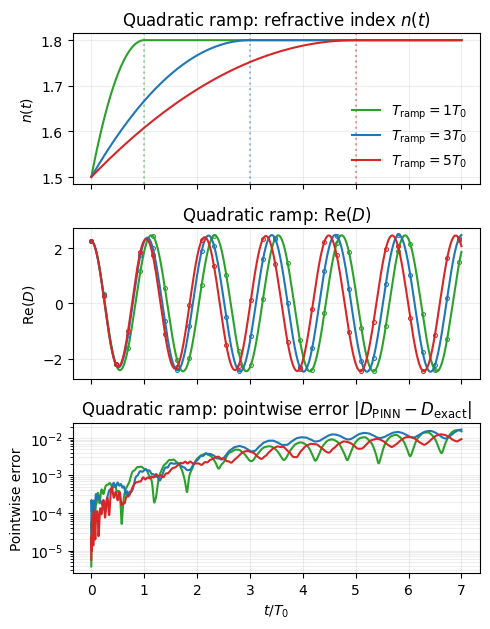

In [ ]:
PLOT_T_MAX = 7.0
PROFILE_COLORS = {1.0: "tab:green", 3.0: "tab:blue", 5.0: "tab:red"}
run_metrics_df = pd.DataFrame(run_metrics)


def representative_prediction(ramp_duration):
    subset = run_metrics_df[
        np.isclose(run_metrics_df["ramp_duration"], ramp_duration)
    ].copy()
    median_error = subset["relative_l2_D_full"].median()
    run = subset.loc[
        (subset["relative_l2_D_full"] - median_error).abs().idxmin()
    ]
    path = Path(run["prediction_file"])
    if not path.exists():
        path = PREDICTIONS_DIR / path.name
    return pd.read_csv(path)


def profile_values(t, duration):
    if "quadratic" == "linear":
        inside = n1 + (n2 - n1) * t / duration
    else:
        a_ramp, b_ramp = quadratic_ramp_parameters(duration)
        inside = n1 * (1.0 + b_ramp * t + a_ramp * t**2)
    return np.where(t <= duration, inside, n2)


predictions = {
    duration: representative_prediction(duration)
    for duration in RAMP_DURATIONS
}

fig, axes = plt.subplots(3, 1, figsize=(5.0, 6.4), sharex=True)
profile_t = np.linspace(0.0, PLOT_T_MAX, 2000)

for duration in RAMP_DURATIONS:
    color = PROFILE_COLORS[duration]
    prediction = predictions[duration]
    mask = prediction["tau"] <= PLOT_T_MAX + 1e-12
    shown = prediction.loc[mask]

    axes[0].plot(
        profile_t, profile_values(profile_t, duration),
        color=color, label=rf"$T_{{\rm ramp}}={duration:g}T_0$",
    )
    axes[0].axvline(duration, color=color, linestyle=":", alpha=0.45)
    axes[1].plot(shown["tau"], shown["D_pred_real"], color=color)
    axes[1].plot(
        shown["tau"], shown["D_true_real"], color=color,
        linestyle="None", marker="o", markevery=max(1, len(shown) // 30),
        markersize=2.8, markerfacecolor="none", markeredgewidth=0.8,
    )
    axes[2].semilogy(
        shown["tau"], np.maximum(shown["D_abs_error"], 1e-12), color=color
    )

axes[0].set_title("Quadratic ramp: refractive index $n(t)$")
axes[0].set_ylabel(r"$n(t)$")
axes[0].legend(frameon=False)
axes[1].set_title(r"Quadratic ramp: Re$(D)$")
axes[1].set_ylabel(r"Re$(D)$")
axes[2].set_title(
    r"Quadratic ramp: pointwise error $|D_{\rm PINN}-D_{\rm exact}|$"
)
axes[2].set_ylabel("Pointwise error")
axes[2].set_xlabel(r"$t/T_0$")
for axis in axes:
    axis.grid(True, which="both", alpha=0.22)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4_quadratic_column.pdf", bbox_inches="tight")
fig.savefig(
    FIGURES_DIR / "figure_4_quadratic_column.png",
    dpi=300, bbox_inches="tight",
)
plt.show()


## Saved results

The notebook saves the configuration, model checkpoints, run-level and
five-run metrics, analytical and PINN predictions, loss histories, the Table 3
rows, and the corresponding Figure 4 column.
